<a href="https://colab.research.google.com/github/matteoriggi07-lang/peru-equities-monte-carlo/blob/main/peru_monte_carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Price data
----------
Credicorp (BAP): 752 trading days, 01 Nov 2023 to 30 Oct 2026, from Yahoo Finance (BAP)
Buenaventura (BVN): 752 trading days, 01 Nov 2023 to 30 Oct 2026, from Yahoo Finance (BVN)
Alicorp (ALICORC1): 742 trading days, 01 Nov 2023 to 30 Oct 2026, from Yahoo Finance (ALICORC1.LM)
The combined NYSE and Lima calendar has 752 trading days.
Days with no quote: Alicorp 10.

Inputs
------
Risk-free rates: USD 3.97% (13-week T-bill), PEN 4.50% (set by hand, update to the BCRP reference rate).


,Data source,Last close,As of,Trading days,Volatility,Past 3y drift,Risk-free rate,Skew,Excess kurtosis,Normality p-value
Credicorp (BAP),Yahoo Finance (BAP),348.96,30 Oct 2026,751,28.2%,43.8%,3.97%,-0.09,5.03,0.000
Buenaventura (BVN),Yahoo Finance (BVN),26.42,30 Oct 2026,751,44.4%,51.3%,3.97%,0.37,6.42,0.000
Alicorp (ALICORC1),Yahoo Finance (ALICORC1.LM),13.22,30 Oct 2026,741,20.3%,35.4%,4.50%,0.85,6.89,0.000



Simulation
----------
Simulated 10,000 one-year paths for each stock, drift set to the risk-free rate.


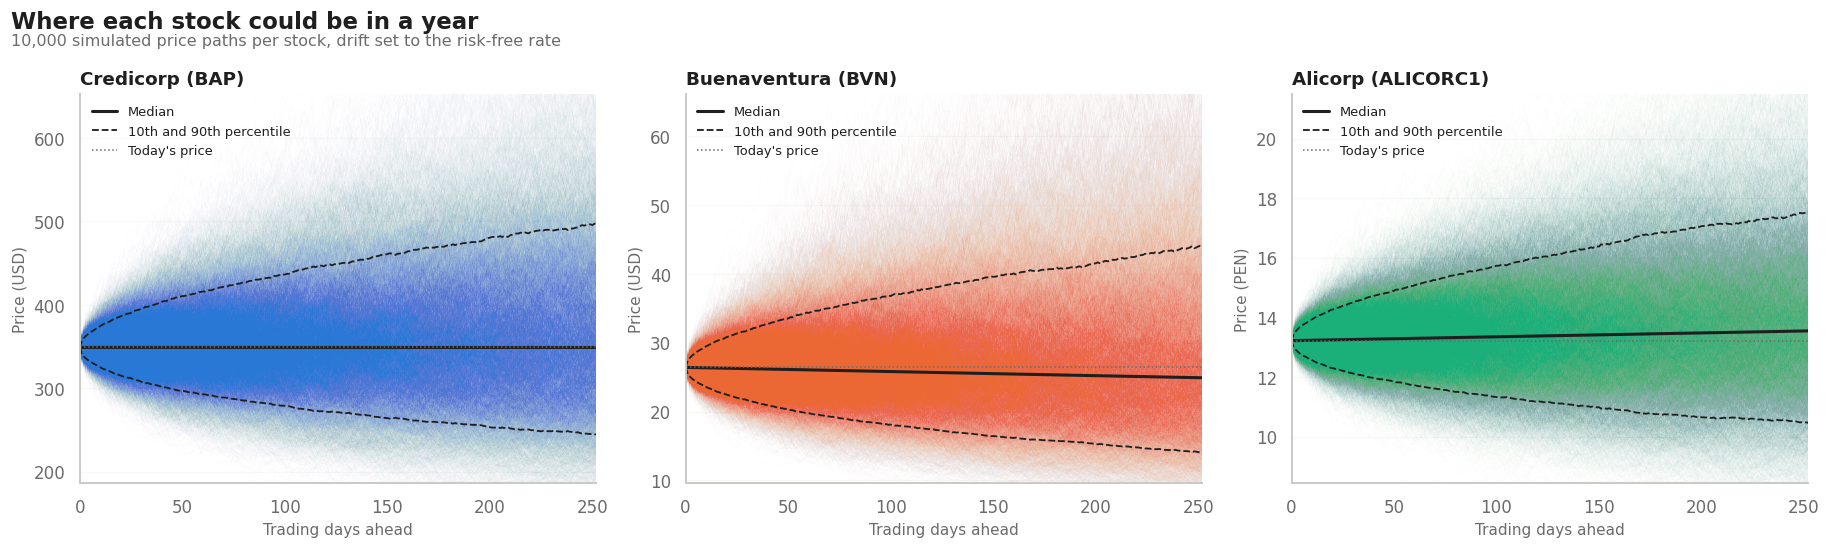

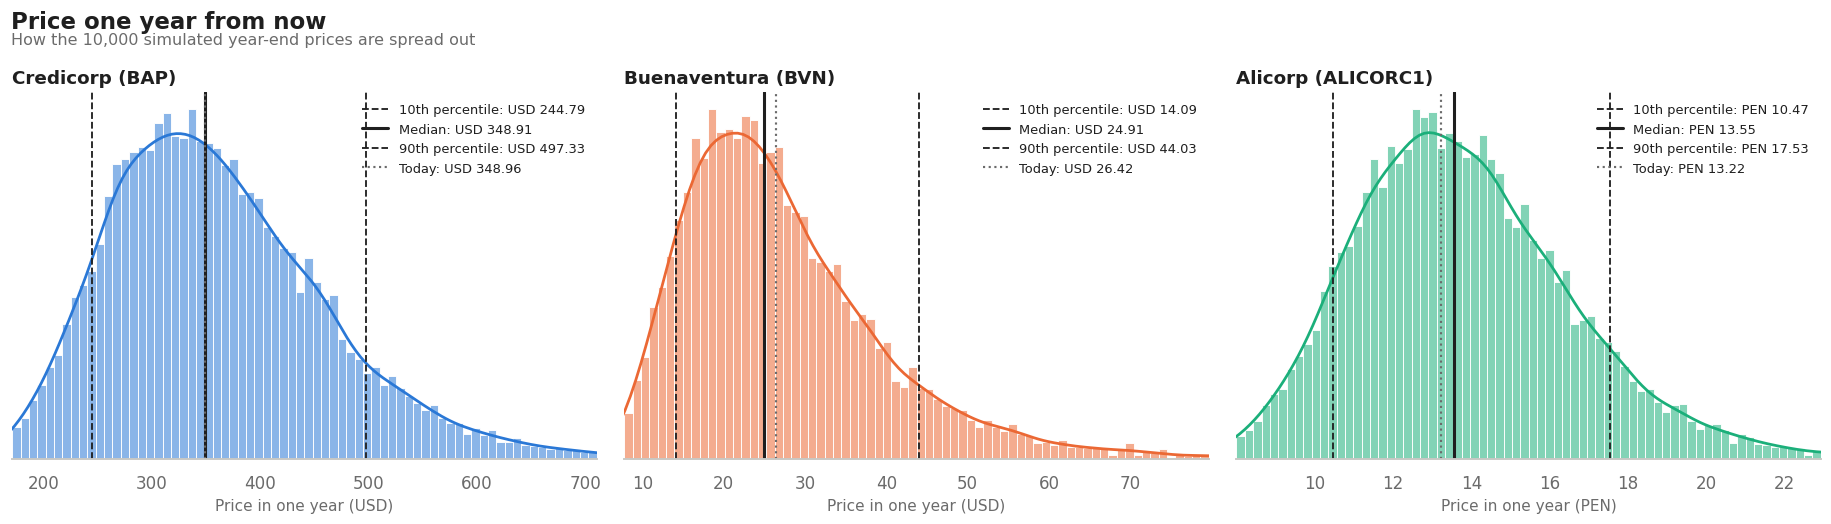

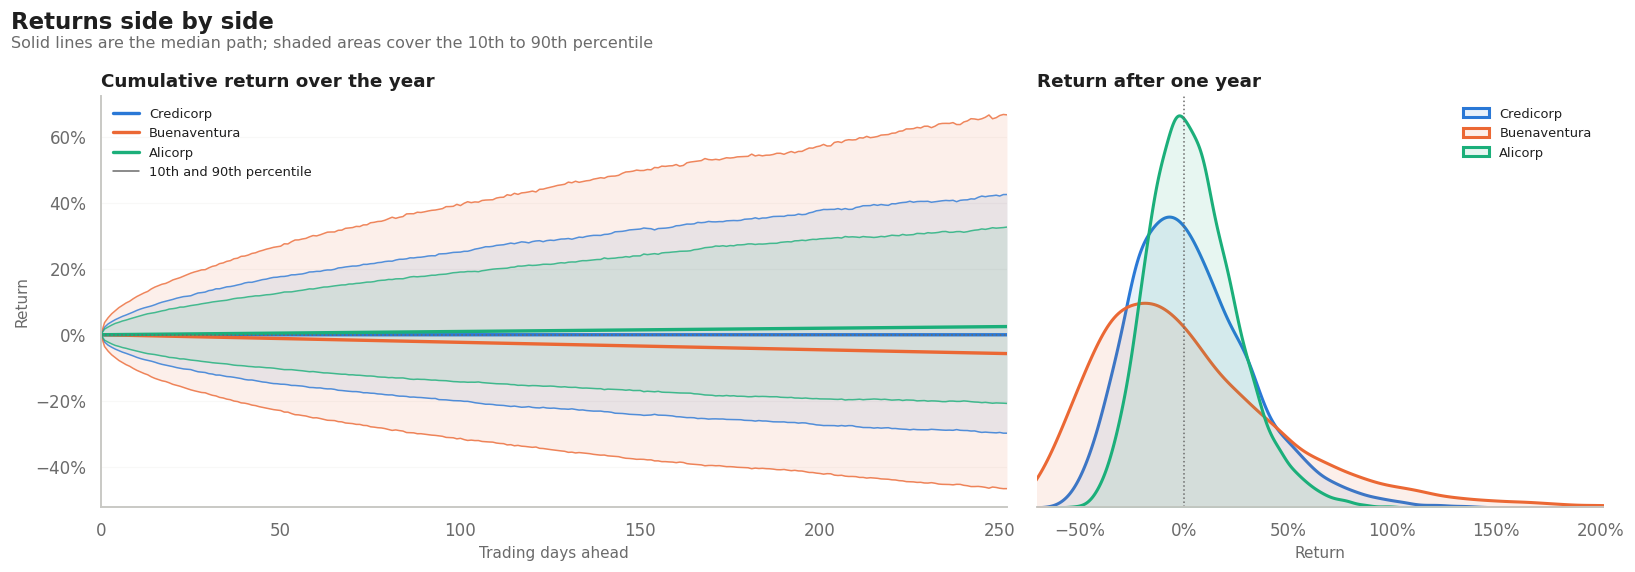


One year out
------------


,Credicorp (BAP),Buenaventura (BVN),Alicorp (ALICORC1)
Price today,USD 348.96,USD 26.42,PEN 13.22
Bad year (10th pct),USD 244.79,USD 14.09,PEN 10.47
Median in one year,USD 348.91,USD 24.91,PEN 13.55
Good year (90th pct),USD 497.33,USD 44.03,PEN 17.53
Median return,0.0%,-5.7%,2.5%
VaR 95%,36.7%,55.1%,26.6%
Expected shortfall 95%,43.3%,62.4%,32.5%
Volatility,28.2%,44.4%,20.3%
Drift assumed,4.0%,4.0%,4.5%
Chance of ending higher,50%,45%,55%



How much the drift assumption matters
-------------------------------------
Same volatility for each stock, three different assumptions about the drift.


Drift Median return VaR 95%  \
Stock              Drift assumption                                
Credicorp (BAP)    Past 3 years      43.8%         48.8%    6.6%   
                   Blend (25% past)  13.9%         10.4%   30.7%   
                   Risk-free          4.0%         -0.1%   37.3%   
Buenaventura (BVN) Past 3 years      51.3%         51.1%   27.3%   
                   Blend (25% past)  15.8%          6.0%   49.0%   
                   Risk-free          4.0%         -5.8%   54.7%   
Alicorp (ALICORC1) Past 3 years      35.4%         39.5%    0.1%   
                   Blend (25% past)  12.2%         10.6%   20.8%   
                   Risk-free          4.5%          2.4%   26.7%   

                                    Chance of ending higher  
Stock              Drift assumption                          
Credicorp (BAP)    Past 3 years                         92%  
                   Blend (25% past)                     64%  
                   Risk-free                            50%  
Buenaventura (BVN) Past 3 years                         82%  
                   Blend (25% past)                     55%  
                   Risk-free                            45%  
Alicorp (ALICORC1) Past 3 years                         95%  
                   Blend (25% past)                     69%  
                   Risk-free                            55%


VaR and expected shortfall are one-year losses as a share of today's price.
The stocks trade in different currencies, so compare percentages, not prices.
Returns for Credicorp, Buenaventura and Alicorp have fatter tails than a normal distribution, so this model probably understates how bad the worst years can get.
Charts and summary.csv are saved in the figures/ folder.


In [4]:

# Monte Carlo simulation of three Peruvian stocks: Credicorp (BAP),
# Buenaventura (BVN) and Alicorp (ALICORC1).
#
# Each stock follows a geometric Brownian motion:
#     S_T = S_0 * exp((mu - sigma^2 / 2) * T + sigma * sqrt(T) * Z)
# Volatility comes from three years of daily returns. The drift is a choice
# (see DRIFT_MODE), because extrapolating the last three years is rarely a
# sensible forecast.
#
# Colab already has every library used here. Elsewhere, install them with:
#     pip install yfinance matplotlib seaborn pandas numpy scipy

import os
import time
import warnings

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")


# Settings

# Yahoo symbols are tried in order. Yahoo's coverage of Lima-listed stocks is
# patchy, so if none of them work the script looks for a CSV with that name.
COMPANIES = {
    "BAP": {"name": "Credicorp", "currency": "USD", "color": "#2a78d6",
            "yahoo": ["BAP"], "csv": "BAP.csv"},
    "BVN": {"name": "Buenaventura", "currency": "USD", "color": "#eb6834",
            "yahoo": ["BVN"], "csv": "BVN.csv"},
    "ALICORC1": {"name": "Alicorp", "currency": "PEN", "color": "#1baf7a",
                 "yahoo": ["ALICORC1.LM", "ALICORC1.PE", "ALICORI1.LM"],
                 "csv": "ALICORC1.csv"},
}

YEARS_OF_HISTORY = 3
N_PATHS = 10_000
HORIZON_DAYS = 252
DAYS_PER_YEAR = 252
CONFIDENCE = 0.95
MAX_FILL_DAYS = 3        # holidays forward-filled in the combined calendar
OUTLIER_CUTOFF = 0.40    # daily log returns beyond ±40% are treated as bad data
SEED = 42
CSV_DAYFIRST = False     # set to True if your CSV uses DD/MM/YYYY dates

# "risk_free": drift equals the risk-free rate of the stock's currency
# "blend":     BLEND_WEIGHT of the historical drift, the rest risk-free
# "historical": the trailing three-year drift (usually far too optimistic)
DRIFT_MODE = "risk_free"
BLEND_WEIGHT = 0.25

# USD is updated from the 13-week T-bill when available.
# PEN has to be set by hand: use the current BCRP reference rate.
RISK_FREE = {"USD": 0.040, "PEN": 0.045}

OUTPUT_DIR = "figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DRIFT_DESCRIPTIONS = {
    "risk_free": "drift set to the risk-free rate",
    "blend": f"drift blends {BLEND_WEIGHT:.0%} of the past three years with the risk-free rate",
    "historical": "drift taken from the past three years",
}
DRIFT_SHORT = {
    "historical": "Past 3 years",
    "blend": f"Blend ({BLEND_WEIGHT:.0%} past)",
    "risk_free": "Risk-free",
}


def pct(x):
    # Rounds first so tiny negatives show as 0.0% instead of -0.0%
    return f"{round(x, 3) + 0.0:.1%}"


# Chart style: neutral ink for text and reference lines, colour only for the stocks

INK = "#1f1f1f"
MUTED = "#6b6b6b"
GRID = "#e6e6e3"

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#c8c8c4",
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "legend.fontsize": 8.5,
    "legend.frameon": False,
    "legend.labelcolor": INK,
})


def label(t):
    return f"{COMPANIES[t]['name']} ({t})"


def section(title):
    print(f"\n{title}\n{'-' * len(title)}")


# Getting and cleaning the data

def date_window(years=YEARS_OF_HISTORY):
    end = pd.Timestamp.today().normalize() + pd.Timedelta(days=1)
    start = end - pd.DateOffset(years=years) - pd.Timedelta(days=1)
    return start, end


def tidy_index(s):
    # NYSE and Lima report in different time zones, so keep only the date
    idx = pd.DatetimeIndex(s.index)
    if idx.tz is not None:
        idx = idx.tz_localize(None)
    s.index = idx.normalize()
    return s[~s.index.duplicated(keep="last")].sort_index().astype(float)


def from_yahoo(symbols, start, end, retries=2):
    for sym in symbols:
        for attempt in range(1, retries + 1):
            try:
                df = yf.download(sym, start=start, end=end, auto_adjust=True,
                                 progress=False, threads=False)
            except Exception:
                df = None
            if df is not None and not df.empty:
                close = df["Close"]
                if isinstance(close, pd.DataFrame):
                    close = close.iloc[:, 0]
                close = tidy_index(close.dropna())
                if len(close) > 60:
                    return close, sym
            time.sleep(attempt)
    return None, None


def from_csv(path, start, end):
    # Works with Yahoo, Investing.com and BVL exports, in English or Spanish
    df = pd.read_csv(path)
    cols = {c.lower().strip().strip('"'): c for c in df.columns}
    date_col = next((cols[k] for k in ("date", "fecha") if k in cols), df.columns[0])
    price_col = next((cols[k] for k in ("adj close", "close", "price", "último",
                                         "ultimo", "cierre") if k in cols), None)
    if price_col is None:
        raise ValueError(f"Couldn't find a price column in {path}: {list(df.columns)}")

    raw = df[price_col].astype(str).str.strip()
    if raw.str.contains(",").all() and not raw.str.contains(r"\.").any():
        raw = raw.str.replace(",", ".", regex=False)   # 12,65 -> 12.65
    else:
        raw = raw.str.replace(",", "", regex=False)    # 1,234.5 -> 1234.5
    s = pd.Series(pd.to_numeric(raw, errors="coerce").values,
                  index=pd.to_datetime(df[date_col], errors="coerce",
                                       dayfirst=CSV_DAYFIRST))
    s = tidy_index(s[s.index.notna()].dropna())
    return s[(s.index >= start) & (s.index < end)]


def load_prices():
    start, end = date_window()
    prices, sources = {}, {}
    for t, info in COMPANIES.items():
        s, sym = from_yahoo(info["yahoo"], start, end)
        if s is not None:
            prices[t], sources[t] = s.rename(t), f"Yahoo Finance ({sym})"
        elif os.path.exists(info["csv"]):
            s = from_csv(info["csv"], start, end)
            if len(s) > 60:
                prices[t], sources[t] = s.rename(t), f"CSV file ({info['csv']})"

        if t in prices:
            s = prices[t]
            print(f"{label(t)}: {len(s)} trading days, "
                  f"{s.index.min():%d %b %Y} to {s.index.max():%d %b %Y}, from {sources[t]}")
        else:
            print(f"{label(t)}: no data found on Yahoo Finance. To include it, upload "
                  f"about three years of daily prices as {info['csv']} and run again.")
    if not prices:
        raise RuntimeError("Couldn't download any prices. Check your connection.")
    return prices, sources


def clean(prices):
    # Returns are computed on each stock's own trading days, so a Peruvian
    # holiday never shows up as a fake 0% day for the NYSE stocks (or vice versa).
    cleaned = {}
    for t, s in prices.items():
        s = s.replace([np.inf, -np.inf], np.nan)
        cleaned[t] = s[s > 0].dropna().sort_index()

    combined = pd.concat(cleaned.values(), axis=1, join="outer").sort_index()
    missing = combined.isna().sum()
    combined = combined.ffill(limit=MAX_FILL_DAYS)

    gaps = [f"{COMPANIES[t]['name']} {n}" for t, n in missing.items() if n > 0]
    print(f"The combined NYSE and Lima calendar has {len(combined)} trading days.")
    print("Days with no quote: " + (", ".join(gaps) if gaps else "none") + ".")
    return cleaned, combined


def risk_free_rates():
    rates = dict(RISK_FREE)
    try:
        irx = yf.download("^IRX", period="1mo", progress=False, auto_adjust=False)
        c = irx["Close"]
        if isinstance(c, pd.DataFrame):
            c = c.iloc[:, 0]
        latest = float(c.dropna().iloc[-1]) / 100
        if 0 < latest < 0.20:
            rates["USD"] = latest
            usd_note = "13-week T-bill"
        else:
            usd_note = "default"
    except Exception:
        usd_note = "default, T-bill download failed"
    print(f"Risk-free rates: USD {rates['USD']:.2%} ({usd_note}), "
          f"PEN {rates['PEN']:.2%} (set by hand, update to the BCRP reference rate).")
    return rates


def pick_drift(mu_hist, rf, mode):
    if mode == "historical":
        return mu_hist
    if mode == "blend":
        return BLEND_WEIGHT * mu_hist + (1 - BLEND_WEIGHT) * rf
    return rf


def estimate(prices, rates):
    rows = []
    for t, s in prices.items():
        r = np.log(s / s.shift(1)).dropna()
        bad = r.abs() > OUTLIER_CUTOFF
        r = r[~bad]

        sigma = r.std(ddof=1) * np.sqrt(DAYS_PER_YEAR)
        mu_hist = r.mean() * DAYS_PER_YEAR + 0.5 * sigma ** 2
        rf = rates[COMPANIES[t]["currency"]]

        rows.append({
            "ticker": t, "S0": float(s.iloc[-1]), "as_of": s.index[-1],
            "days": len(r), "outliers": int(bad.sum()),
            "sigma": sigma, "mu_hist": mu_hist, "rf": rf,
            "mu": pick_drift(mu_hist, rf, DRIFT_MODE),
            "skew": stats.skew(r), "kurt": stats.kurtosis(r),
            "jb_p": stats.jarque_bera(r).pvalue,
        })
    return pd.DataFrame(rows).set_index("ticker")


# Simulation

def simulate(S0, mu, sigma, n=N_PATHS, steps=HORIZON_DAYS, dt=1 / DAYS_PER_YEAR, rng=None):
    # Antithetic draws (Z and -Z) give the same accuracy with fewer paths
    rng = rng if rng is not None else np.random.default_rng()
    Z = rng.standard_normal((n // 2, steps))
    Z = np.vstack([Z, -Z])
    if n % 2:
        Z = np.vstack([Z, rng.standard_normal((1, steps))])

    steps_log = (mu - 0.5 * sigma ** 2) * dt + sigma * np.sqrt(dt) * Z
    log_paths = np.concatenate([np.zeros((n, 1)), np.cumsum(steps_log, axis=1)], axis=1)
    return S0 * np.exp(log_paths)


def risk_metrics(final_prices, S0, confidence=CONFIDENCE):
    ret = final_prices / S0 - 1
    p10, p50, p90 = np.percentile(final_prices, [10, 50, 90])
    cutoff = np.percentile(ret, (1 - confidence) * 100)
    return {
        "S0": S0, "P10": p10, "P50": p50, "P90": p90,
        "median_ret": p50 / S0 - 1,
        "VaR": -cutoff,
        "CVaR": -ret[ret <= cutoff].mean(),
        "p_gain": (ret > 0).mean(),
    }


def drift_comparison(params, n=200_000):
    # One-year prices under GBM are lognormal, so we can draw them directly
    Z = np.random.default_rng(SEED).standard_normal(n)
    rows = []
    for t, p in params.iterrows():
        for mode in ("historical", "blend", "risk_free"):
            mu = pick_drift(p["mu_hist"], p["rf"], mode)
            ST = p["S0"] * np.exp(mu - 0.5 * p["sigma"] ** 2 + p["sigma"] * Z)
            m = risk_metrics(ST, p["S0"])
            rows.append({
                "Stock": label(t), "Drift assumption": DRIFT_SHORT[mode],
                "Drift": pct(mu), "Median return": pct(m["median_ret"]),
                f"VaR {CONFIDENCE:.0%}": pct(m["VaR"]),
                "Chance of ending higher": f"{m['p_gain']:.0%}",
            })
    return pd.DataFrame(rows).set_index(["Stock", "Drift assumption"])


# Charts

def visible_range(x, lo=0.5, hi=99.5):
    # Trim the extreme 1% so a few wild paths don't flatten the chart
    return np.percentile(x, lo), np.percentile(x, hi)


def titles(fig, title, subtitle):
    fig.suptitle(title, x=0.01, y=1.08, ha="left", fontsize=15,
                 fontweight="bold", color=INK)
    fig.text(0.01, 1.01, subtitle, ha="left", fontsize=10.5, color=MUTED)


def save(fig, filename):
    fig.savefig(os.path.join(OUTPUT_DIR, filename), bbox_inches="tight", facecolor="white")
    plt.show()


def chart_paths(sims, params):
    tickers = list(sims)
    fig, axes = plt.subplots(1, len(tickers), figsize=(5.6 * len(tickers), 4.6))
    axes = np.atleast_1d(axes)
    days = np.arange(HORIZON_DAYS + 1)

    for ax, t in zip(axes, tickers):
        paths, info = sims[t], COMPANIES[t]
        segments = np.stack([np.broadcast_to(days, paths.shape), paths], axis=-1)
        ax.add_collection(LineCollection(segments, colors=info["color"], linewidths=0.3,
                                         alpha=0.015, rasterized=True))
        p10, p50, p90 = np.percentile(paths, [10, 50, 90], axis=0)
        ax.plot(days, p50, color=INK, lw=2, label="Median")
        ax.plot(days, p10, color=INK, lw=1.2, ls="--", label="10th and 90th percentile")
        ax.plot(days, p90, color=INK, lw=1.2, ls="--")
        ax.axhline(params.loc[t, "S0"], color=MUTED, lw=1, ls=":", label="Today's price")

        lo, hi = visible_range(paths)
        ax.set_xlim(0, HORIZON_DAYS)
        ax.set_ylim(max(lo * 0.95, 0), hi * 1.05)
        ax.set_title(label(t))
        ax.set_xlabel("Trading days ahead")
        ax.set_ylabel(f"Price ({info['currency']})")
        ax.legend(loc="upper left")

    plt.tight_layout()
    titles(fig, "Where each stock could be in a year",
           f"{N_PATHS:,} simulated price paths per stock, {DRIFT_DESCRIPTIONS[DRIFT_MODE]}")
    save(fig, "1_price_paths.png")


def chart_final_prices(sims, metrics):
    tickers = list(sims)
    fig, axes = plt.subplots(1, len(tickers), figsize=(5.6 * len(tickers), 4.4))
    axes = np.atleast_1d(axes)

    for ax, t in zip(axes, tickers):
        ST, m, info = sims[t][:, -1], metrics[t], COMPANIES[t]
        lo, hi = visible_range(ST)
        sns.histplot(ST, bins=70, binrange=(lo, hi), stat="density",
                     color=info["color"], alpha=0.55, edgecolor="white", linewidth=0.6,
                     kde=True, line_kws={"lw": 1.8}, ax=ax)
        cur = info["currency"]
        ax.axvline(m["P10"], color=INK, ls="--", lw=1.2, label=f"10th percentile: {cur} {m['P10']:,.2f}")
        ax.axvline(m["P50"], color=INK, ls="-", lw=2, label=f"Median: {cur} {m['P50']:,.2f}")
        ax.axvline(m["P90"], color=INK, ls="--", lw=1.2, label=f"90th percentile: {cur} {m['P90']:,.2f}")
        ax.axvline(m["S0"], color=MUTED, ls=":", lw=1.4, label=f"Today: {cur} {m['S0']:,.2f}")

        ax.set_xlim(lo, hi)
        ax.set_yticks([])
        ax.set_ylabel("")
        ax.grid(False)
        ax.spines["left"].set_visible(False)
        ax.set_title(label(t))
        ax.set_xlabel(f"Price in one year ({cur})")
        ax.legend(loc="upper right")

    plt.tight_layout()
    titles(fig, "Price one year from now",
           f"How the {N_PATHS:,} simulated year-end prices are spread out")
    save(fig, "2_price_in_one_year.png")


def chart_returns(sims):
    fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8),
                                      gridspec_kw={"width_ratios": [1.6, 1]})
    days = np.arange(HORIZON_DAYS + 1)
    x_lo, x_hi = np.inf, -np.inf

    for t, paths in sims.items():
        color, name = COMPANIES[t]["color"], COMPANIES[t]["name"]
        cum = paths / paths[:, [0]] - 1
        p10, p50, p90 = np.percentile(cum, [10, 50, 90], axis=0)

        left.fill_between(days, p10, p90, color=color, alpha=0.10, lw=0)
        left.plot(days, p10, color=color, lw=1, alpha=0.8)
        left.plot(days, p90, color=color, lw=1, alpha=0.8)
        left.plot(days, p50, color=color, lw=2.2, label=name)

        final = cum[:, -1]
        sns.kdeplot(final, color=color, lw=2, fill=True, alpha=0.10,
                    gridsize=512, label=name, ax=right)
        lo, hi = visible_range(final)
        x_lo, x_hi = min(x_lo, lo), max(x_hi, hi)

    left.axhline(0, color=MUTED, lw=1, ls=":")
    left.set_xlim(0, HORIZON_DAYS)
    left.set_title("Cumulative return over the year")
    left.set_xlabel("Trading days ahead")
    left.set_ylabel("Return")
    left.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    handles, labels_ = left.get_legend_handles_labels()
    handles.append(Line2D([0], [0], color=MUTED, lw=1))
    labels_.append("10th and 90th percentile")
    left.legend(handles, labels_, loc="upper left")

    right.axvline(0, color=MUTED, lw=1, ls=":")
    right.set_xlim(x_lo, x_hi)
    right.set_title("Return after one year")
    right.set_xlabel("Return")
    right.set_yticks([])
    right.set_ylabel("")
    right.grid(False)
    right.spines["left"].set_visible(False)
    right.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    right.legend(loc="upper right")

    plt.tight_layout()
    titles(fig, "Returns side by side",
           "Solid lines are the median path; shaded areas cover the 10th to 90th percentile")
    save(fig, "3_returns_compared.png")


# Tables

def parameter_table(params, sources):
    table = pd.DataFrame({
        "Data source": pd.Series(sources),
        "Last close": params["S0"].map("{:,.2f}".format),
        "As of": params["as_of"].dt.strftime("%d %b %Y"),
        "Trading days": params["days"],
        "Volatility": params["sigma"].map("{:.1%}".format),
        "Past 3y drift": params["mu_hist"].map("{:.1%}".format),
        "Risk-free rate": params["rf"].map("{:.2%}".format),
        "Skew": params["skew"].map("{:.2f}".format),
        "Excess kurtosis": params["kurt"].map("{:.2f}".format),
        "Normality p-value": params["jb_p"].map("{:.3f}".format),
    }).loc[params.index]
    table.index = [label(t) for t in table.index]
    return table


def summary_tables(params, metrics):
    rows = []
    for t in params.index:
        m, p, info = metrics[t], params.loc[t], COMPANIES[t]
        rows.append({
            "Stock": label(t), "Currency": info["currency"],
            "Price today": m["S0"], "Bad year (10th pct)": m["P10"],
            "Median in one year": m["P50"], "Good year (90th pct)": m["P90"],
            "Median return": m["median_ret"], f"VaR {CONFIDENCE:.0%}": m["VaR"],
            f"Expected shortfall {CONFIDENCE:.0%}": m["CVaR"],
            "Volatility": p["sigma"], "Drift assumed": p["mu"],
            "Chance of ending higher": m["p_gain"],
        })
    numbers = pd.DataFrame(rows).set_index("Stock")
    numbers.to_csv(os.path.join(OUTPUT_DIR, "summary.csv"))

    pretty = numbers.copy().astype(object)
    for s in pretty.index:
        cur = numbers.loc[s, "Currency"]
        for col in ["Price today", "Bad year (10th pct)", "Median in one year",
                    "Good year (90th pct)"]:
            pretty.loc[s, col] = f"{cur} {numbers.loc[s, col]:,.2f}"
        for col in ["Median return", f"VaR {CONFIDENCE:.0%}",
                    f"Expected shortfall {CONFIDENCE:.0%}", "Volatility", "Drift assumed"]:
            pretty.loc[s, col] = pct(numbers.loc[s, col])
        pretty.loc[s, "Chance of ending higher"] = f"{numbers.loc[s, 'Chance of ending higher']:.0%}"
    pretty = pretty.drop(columns="Currency").T
    pretty.columns.name = None
    return numbers, pretty


# Run everything

def main():
    section("Price data")
    raw, sources = load_prices()
    prices, _ = clean(raw)

    section("Inputs")
    rates = risk_free_rates()
    params = estimate(prices, rates)
    display(parameter_table(params, sources))

    section("Simulation")
    sims, metrics = {}, {}
    for i, t in enumerate(params.index):
        p = params.loc[t]
        sims[t] = simulate(p["S0"], p["mu"], p["sigma"], rng=np.random.default_rng(SEED + i))
        metrics[t] = risk_metrics(sims[t][:, -1], p["S0"])
    print(f"Simulated {N_PATHS:,} one-year paths for each stock, "
          f"{DRIFT_DESCRIPTIONS[DRIFT_MODE]}.")

    chart_paths(sims, params)
    chart_final_prices(sims, metrics)
    chart_returns(sims)

    section("One year out")
    numbers, pretty = summary_tables(params, metrics)
    display(pretty)

    section("How much the drift assumption matters")
    print("Same volatility for each stock, three different assumptions about the drift.")
    display(drift_comparison(params))

    fat_tails = [COMPANIES[t]["name"] for t in params.index if params.loc[t, "jb_p"] < 0.05]
    currencies = sorted({COMPANIES[t]["currency"] for t in params.index})
    print()
    print("VaR and expected shortfall are one-year losses as a share of today's price.")
    if len(currencies) > 1:
        print("The stocks trade in different currencies, so compare percentages, not prices.")
    if fat_tails:
        names = fat_tails[0] if len(fat_tails) == 1 else ", ".join(fat_tails[:-1]) + " and " + fat_tails[-1]
        print(f"Returns for {names} have fatter tails than a normal distribution, "
              f"so this model probably understates how bad the worst years can get.")
    print(f"Charts and summary.csv are saved in the {OUTPUT_DIR}/ folder.")
    return numbers, sims, params


summary, sims, params = main()